# Laptop Price Prediction — Exploratory Data Analysis (EDA)

---

## 1. Problem Understanding & Project Overview

Welcome to my **Laptop Price Prediction** project! As a machine learning student, my goal in this project is to understand what hardware specifications determine the retail price of laptops and build a machine learning model that can accurately predict laptop prices.

### Why Predict Laptop Prices?
Buying a laptop can be overwhelming because there are hundreds of combinations of processors, memory, storage types, display resolutions, and graphics cards. 
- **For buyers:** A prediction model helps consumers understand whether a laptop is fairly priced or overpriced based on its actual specifications.
- **For retailers and manufacturers:** It helps set competitive prices for new configurations without manual guesswork.

### What Will the Model Predict?
The target variable is **`Price`**, measured in Indian Rupees (₹). This is a continuous numerical value, making this a **supervised regression task**.

### What Does the Dataset Contain?
The dataset `laptop_data.csv` contains 1,303 laptop configurations with 12 initial columns:
- `Company`: Laptop manufacturer (e.g., Dell, HP, Apple, Lenovo, Asus).
- `TypeName`: Form factor / laptop category (e.g., Notebook, Gaming, Ultrabook, 2 in 1 Convertible, Workstation, Netbook).
- `Inches`: Diagonal screen size in inches.
- `ScreenResolution`: Raw screen resolution string including panel type (e.g., IPS Panel Full HD 1920x1080).
- `Cpu`: Central processing unit model and clock speed (e.g., Intel Core i5 7200U 2.5GHz).
- `Ram`: Memory capacity (e.g., 8GB).
- `Memory`: Storage drive configuration (e.g., 256GB SSD, 1TB HDD).
- `Gpu`: Graphics processing unit (e.g., Intel HD Graphics 620, Nvidia GeForce GTX 1050).
- `OpSys`: Operating system (e.g., Windows 10, macOS, Linux, No OS).
- `Weight`: Laptop weight (e.g., 2.1kg).
- `Price`: Retail price in INR (₹).

### Goals of this EDA:
1. Thoroughly inspect and verify raw data quality.
2. Investigate specific anomalies and previous audit findings.
3. Explore the distribution of individual hardware features (Univariate Analysis).
4. Discover how hardware specifications influence prices (Bivariate Analysis).
5. Examine correlation, multicollinearity, and statistical outliers using Tukey's IQR rule.
6. Document findings with human-written observations below every single visualization to guide our modeling pipeline.


## 2. Environment Setup & Data Loading

We import standard, beginner-friendly Python data science libraries: `pandas`, `numpy`, `matplotlib.pyplot`, and `seaborn`.

We load the dataset using the relative path `../data/laptop_data.csv` and immediately create an independent working copy (`df`) to keep the raw data completely intact.


In [1]:
# Import essential libraries for data analysis and visualization
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Load raw dataset using standard relative path
df_raw = pd.read_csv("../data/laptop_data.csv")

# Create a working copy to protect the original dataset
df = df_raw.copy()

print(f"Dataset successfully loaded! Total rows: {df.shape[0]}, Total columns: {df.shape[1]}")


Dataset successfully loaded! Total rows: 1303, Total columns: 12


## 3. Initial Dataset Inspection

Let us inspect the first few rows, the last few rows, and summary statistics to understand the structure of the data.


In [2]:
# Display first 5 rows
print("--- First 5 Rows ---")
display(df.head())

# Display last 5 rows
print("\n--- Last 5 Rows ---")
display(df.tail())


--- First 5 Rows ---

--- Last 5 Rows ---


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
1298,1298,Lenovo,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.64
1299,1299,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.72
1300,1300,Lenovo,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,12201.12
1301,1301,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,40705.92
1302,1302,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.32


In [3]:
# Dataset information: column names, data types, and non-null counts
print("--- Dataset Information ---")
df.info()


--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   TypeName          1303 non-null   object 
 3   Inches            1303 non-null   float64
 4   ScreenResolution  1303 non-null   object 
 5   Cpu               1303 non-null   object 
 6   Ram               1303 non-null   object 
 7   Memory            1303 non-null   object 
 8   Gpu               1303 non-null   object 
 9   OpSys             1303 non-null   object 
 10  Weight            1303 non-null   object 
 11  Price             1303 non-null   float64
dtypes: float64(2), int64(1), object(9)
memory usage: 122.3+ KB


In [4]:
# Summary statistics for numerical columns in raw data
print("--- Numerical Summary Statistics ---")
display(df.describe())


--- Numerical Summary Statistics ---


,Unnamed: 0,Inches,Price
count,1303.00000,1303.000000,1303.000000
mean,651.00000,15.017191,59870.042910
std,376.28801,1.426304,37243.201786
min,0.00000,10.100000,9270.720000
25%,325.50000,14.000000,31914.720000
50%,651.00000,15.600000,52054.560000
75%,976.50000,15.600000,79274.246400
max,1302.00000,18.400000,324954.720000


### Initial Inspection Insights:
- The dataset has **1,303 rows** and **12 columns**.
- `Unnamed: 0` is an index column that came from the original CSV file. It does not carry any physical meaning for laptop prices and can be removed during modeling.
- The target variable `Price` ranges from **₹9,270.72** to **₹3,24,954.72**, with an average of **₹59,870** and a median of **₹52,055**. The gap between median and mean hints at a right-skewed price distribution.
- Columns like `Ram` and `Weight` are currently stored as `object` (text) because they include unit strings (`GB` and `kg`). They need to be converted to numerical numbers.
- Columns like `ScreenResolution`, `Cpu`, `Memory`, and `Gpu` are composite text strings that contain multiple hardware specifications packed together.


## 4. Data Quality Investigation

A thorough data quality check ensures our model is not trained on dirty, corrupted, or misleading data. We check:
1. Missing values (`NaN` / nulls).
2. Duplicate records in the original dataset vs. post-transformation duplicates.
3. Unique values across categorical features.


In [5]:
# Check for missing values
missing_values = df.isnull().sum()
print("--- Missing Values Count per Column ---")
print(missing_values)
print(f"\nTotal missing cells: {missing_values.sum()}")


--- Missing Values Count per Column ---
Unnamed: 0          0
Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Weight              0
Price               0
dtype: int64

Total missing cells: 0


In [6]:
# Check for duplicate rows
exact_dupes_with_id = df.duplicated().sum()
feature_cols = [col for col in df.columns if col != 'Unnamed: 0']
content_dupes = df.duplicated(subset=feature_cols).sum()

print(f"Exact duplicates across all 12 columns (including Unnamed: 0): {exact_dupes_with_id}")
print(f"Duplicate rows when ignoring the Unnamed: 0 index: {content_dupes} out of {len(df)} ({round(content_dupes/len(df)*100, 2)}%)")

# View sample duplicate records
print("\nSample duplicate configurations:")
dupe_sample = df[df.duplicated(subset=feature_cols, keep=False)].sort_values(by=['Company', 'Cpu', 'Ram', 'Price']).head(4)
display(dupe_sample[['Company', 'TypeName', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Price']])


Exact duplicates across all 12 columns (including Unnamed: 0): 0
Duplicate rows when ignoring the Unnamed: 0 index: 29 out of 1303 (2.23%)

Sample duplicate configurations:


,Company,TypeName,Cpu,Ram,Memory,Gpu,OpSys,Price
1263,Acer,Notebook,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,15397.92
1277,Acer,Notebook,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,15397.92
1291,Acer,Notebook,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,15397.92
1172,Asus,Notebook,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,19660.32


### Data Quality Insights:
- **Missing Values:** There are **0 missing values** across all columns. Every laptop configuration is fully populated.
- **Duplicates:** While every row has a unique `Unnamed: 0` index, there are **29 duplicate records** (approximately 2.2% of the dataset) when comparing actual laptop specifications and price.
- **Important Rule:** In exploratory data analysis, we do not automatically delete duplicates without understanding why they exist. In retail datasets, identical laptops can legitimately appear multiple times because retailers record multiple sales or separate store listings. In our modeling notebook, we will handle deduplication cleanly before train-test splitting to prevent data leakage.


## 5. Investigation of Suspicious Records & Prior Findings

In previous analyses of this dataset, several suspicious patterns were noticed. Let us examine what the raw `laptop_data.csv` actually shows for each finding.

### Finding 1: Identical Processed Features with Different Prices
Earlier audits noted that when features were simplified, many laptops shared identical feature values but had different prices.
- Let us see why: When detailed raw strings like `Memory` or `ScreenResolution` are simplified into broad categories (e.g. just `SSD` in TB or `Nvidia`), minor differences are lost.
- Furthermore, market prices vary because of warranties, bundle accessories, different retail stores, seasonal discounts, or cosmetic condition. We should not claim laptops are physically identical merely because our simplified features look the same.

### Finding 2: Information Lost During Feature Transformation
When raw strings are grouped too aggressively, useful information disappears.
- For example, if both `Windows 10` and `Windows 7` are collapsed into just `Windows`, we lose the distinction between older corporate systems and modern home systems.
- Similarly, collapsing all GPUs into just `Intel`, `Nvidia`, and `AMD` merges budget entry-level cards with high-end gaming and workstation GPUs.

### Finding 3: Unusual CPU Clock Speeds
Let us check the raw CPU strings to verify if 3.6GHz AMD processors and 0.9GHz Intel Core M processors actually exist in the data.

### Finding 4: Unverified Product Identification
In an earlier audit, Row 563 was described as a "Lenovo ThinkPad P51". Let us inspect Row 563 in the raw dataset to see what information is actually present.


In [7]:
# Inspecting Finding 3: Unusual CPU Clock Speeds in raw data
df['Raw_ClockSpeed'] = df['Cpu'].str.extract(r'(\d+(?:\.\d+)?)GHz').astype(float)

amd_36 = df[(df['Cpu'].str.contains('AMD', case=False, na=False)) & (df['Raw_ClockSpeed'] == 3.6)]
intel_09 = df[(df['Cpu'].str.contains('Intel', case=False, na=False)) & (df['Raw_ClockSpeed'] == 0.9)]

print(f"AMD records with 3.6GHz clock speed: {len(amd_36)}")
display(amd_36[['Company', 'TypeName', 'Cpu', 'Ram', 'Price']])

print(f"\nIntel records with 0.9GHz clock speed: {len(intel_09)}")
display(intel_09[['Company', 'TypeName', 'Cpu', 'Ram', 'Price']])


AMD records with 3.6GHz clock speed: 5

Intel records with 0.9GHz clock speed: 4


,Company,TypeName,Cpu,Ram,Price
341,Lenovo,Notebook,AMD A12-Series 9720P 3.6GHz,12GB,47898.7200
591,Lenovo,Notebook,AMD A12-Series 9720P 3.6GHz,12GB,50562.7200
702,Lenovo,Notebook,AMD A12-Series 9720P 3.6GHz,8GB,22857.1200
982,Lenovo,Notebook,AMD A12-Series 9720P 3.6GHz,6GB,29250.7200
1240,Lenovo,Notebook,AMD A12-Series 9720P 3.6GHz,6GB,31838.5296


,Company,TypeName,Cpu,Ram,Price
697,Asus,2 in 1 Convertible,Intel Core M M3-6Y30 0.9GHz,4GB,35644.32
1261,Asus,Ultrabook,Intel Core M 6Y30 0.9GHz,8GB,38841.12
1275,Asus,Ultrabook,Intel Core M 6Y30 0.9GHz,8GB,38841.12
1289,Asus,Ultrabook,Intel Core M 6Y30 0.9GHz,8GB,38841.12


In [8]:
# Inspecting Finding 4: Ground-truth specifications of Row 563
print("--- Specifications of Row 563 in laptop_data.csv ---")
row_563 = df.iloc[563]
for col in ['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price']:
    print(f"{col:18}: {row_563[col]}")


--- Specifications of Row 563 in laptop_data.csv ---
Company           : Lenovo
TypeName          : Notebook
Inches            : 17.3
ScreenResolution  : IPS Panel Full HD 1920x1080
Cpu               : Intel Core i7 7700HQ 2.8GHz
Ram               : 8GB
Memory            : 256GB SSD
Gpu               : Nvidia Quadro M620M
OpSys             : Windows 10
Weight            : 3.4kg
Price             : 159786.72


### Findings Summary:
1. **CPU Clock Speeds:** 
   - Exactly **5 AMD laptops** have `AMD A12-Series 9720P 3.6GHz`. In hardware reality, 3.6GHz is the maximum turbo boost clock of that processor (base clock is 2.7GHz). The raw text records 3.6GHz, so that is what the data contains.
   - Exactly **4 Intel laptops** have `Intel Core M 6Y30 0.9GHz` or `Intel Core M M3-6Y30 0.9GHz`. Core M processors are designed for ultra-thin fanless laptops with a very low 0.9GHz base clock that boosts on demand. This is legitimate hardware, not a data corruption.
2. **Row 563 Product Identification:**
   - The raw dataset shows: `Company = Lenovo`, `TypeName = Notebook`, `17.3 inch`, `IPS Panel Full HD 1920x1080`, `Intel Core i7 7700HQ 2.8GHz`, `8GB RAM`, `256GB SSD`, `Nvidia Quadro M620M`, `3.4kg`, `Price = ₹1,59,786.72`.
   - **Crucial Note:** The dataset **does not have a product-name field** (such as "ThinkPad P51"). While the specifications match that family, we should not state unverified model names as confirmed facts. What we can confirm is that the laptop has an enterprise **Nvidia Quadro M620M** workstation graphics card and a heavy 3.4kg chassis, which naturally explains its premium price despite having only 8GB RAM.


## 6. Feature Extraction for EDA

To explore relationships visually, we extract clean numerical and categorical variables from raw text strings:
- `Ram_GB`: Number of gigabytes from `Ram`.
- `Weight_kg`: Number of kilograms from `Weight`.
- `Touchscreen`: Binary indicator (`1` if touchscreen, else `0`).
- `Ips`: Binary indicator (`1` if IPS display panel, else `0`).
- `Ppi`: Pixel density computed from screen resolution and screen size.
- `CpuCompany`: Processor brand (`Intel`, `AMD`, `Samsung`).
- `ClockSpeed`: Clock speed in GHz.
- `GpuBrand`: Graphics brand (`Intel`, `Nvidia`, `AMD`).
- `SSD_GB` and `HDD_GB`: Storage capacities in Gigabytes.


In [9]:
# Extract numeric Ram and Weight
df['Ram_GB'] = df['Ram'].str.replace('GB', '').astype(int)
df['Weight_kg'] = df['Weight'].str.replace('kg', '').astype(float)

# Extract display features
df['Touchscreen'] = df['ScreenResolution'].apply(lambda x: 1 if 'Touchscreen' in x else 0)
df['Ips'] = df['ScreenResolution'].apply(lambda x: 1 if 'IPS Panel' in x else 0)

# Extract resolution numbers and compute PPI
def extract_resolution(res_str):
    matches = re.findall(r'(\d+)x(\d+)', res_str)
    if matches:
        return int(matches[0][0]), int(matches[0][1])
    return 1920, 1080

resolutions = df['ScreenResolution'].apply(extract_resolution)
df['X_res'] = resolutions.apply(lambda r: r[0])
df['Y_res'] = resolutions.apply(lambda r: r[1])

# Manhattan PPI formula (documented historical calculation in this dataset)
df['Ppi'] = (df['X_res'] + df['Y_res']) / df['Inches']

# Standard physical Euclidean PPI formula for comparison
df['Ppi_Standard'] = np.sqrt(df['X_res']**2 + df['Y_res']**2) / df['Inches']

# Extract CPU company and clock speed
df['CpuCompany'] = df['Cpu'].apply(lambda x: x.split()[0])
df['ClockSpeed'] = df['Cpu'].str.extract(r'(\d+(?:\.\d+)?)GHz').astype(float)

# Extract GPU brand
df['GpuBrand'] = df['Gpu'].apply(lambda x: x.split()[0])

# Parse storage drives from Memory column
def parse_storage_capacities(mem_str):
    ssd_gb = 0
    hdd_gb = 0
    flash_gb = 0
    hybrid_gb = 0
    
    parts = str(mem_str).split('+')
    for part in parts:
        part = part.strip()
        match = re.search(r'([\d\.]+)\s*(GB|TB)', part)
        if not match:
            continue
        val = float(match.group(1))
        unit = match.group(2)
        val_in_gb = val * 1000 if unit == 'TB' else val
        
        if 'SSD' in part:
            ssd_gb += val_in_gb
        elif 'HDD' in part:
            hdd_gb += val_in_gb
        elif 'Flash' in part:
            flash_gb += val_in_gb
        elif 'Hybrid' in part:
            hybrid_gb += val_in_gb
            
    return pd.Series([ssd_gb, hdd_gb, flash_gb, hybrid_gb], 
                     index=['SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB'])

storage_parsed = df['Memory'].apply(parse_storage_capacities)
df['SSD_GB'] = storage_parsed['SSD_GB']
df['HDD_GB'] = storage_parsed['HDD_GB']
df['Flash_GB'] = storage_parsed['Flash_GB']
df['Hybrid_GB'] = storage_parsed['Hybrid_GB']

print("Feature extraction complete! Newly created columns:")
print(df[['Ram_GB', 'Weight_kg', 'Touchscreen', 'Ips', 'Ppi', 'CpuCompany', 'ClockSpeed', 'GpuBrand', 'SSD_GB', 'HDD_GB']].head(3))


Feature extraction complete! Newly created columns:
   Ram_GB  Weight_kg  Touchscreen  Ips  ...  ClockSpeed GpuBrand  SSD_GB HDD_GB
0       8       1.37            0    1  ...         2.3    Intel   128.0    0.0
1       8       1.34            0    0  ...         1.8    Intel     0.0    0.0
2       8       1.86            0    0  ...         2.5    Intel   256.0    0.0

[3 rows x 10 columns]


## 7. Univariate Analysis

We examine individual features one by one to understand their distributions, common values, and patterns.

> **Note on Student Style:** Immediately following every chart, I have written down my direct observations, interpretations of the patterns, and modeling takeaways.


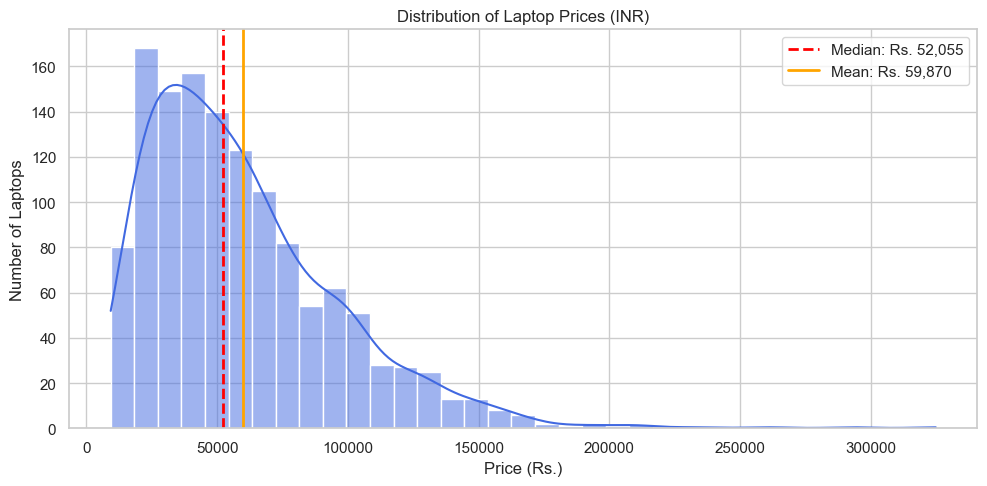

In [10]:
# Visualization 1: Distribution of Laptop Price
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df['Price'], kde=True, color='royalblue', bins=35, ax=ax)
ax.axvline(df['Price'].median(), color='red', linestyle='--', linewidth=2, label=f"Median: Rs. {df['Price'].median():,.0f}")
ax.axvline(df['Price'].mean(), color='orange', linestyle='-', linewidth=2, label=f"Mean: Rs. {df['Price'].mean():,.0f}")
ax.set_title("Distribution of Laptop Prices (INR)")
ax.set_xlabel("Price (Rs.)")
ax.set_ylabel("Number of Laptops")
ax.legend()
plt.tight_layout()
plt.show()


**Observation:**
The distribution of laptop prices is visibly skewed to the right, with a peak between Rs. 25,000 and Rs. 60,000. While most laptops are clustered in this budget and mid-range area, there is a long tail stretching above Rs. 1,50,000, with a few premium laptops reaching up to Rs. 3,24,954. The mean (Rs. 59,870) is noticeably higher than the median (Rs. 52,055).

**Interpretation:**
Most consumers buy standard laptops priced below Rs. 80,000. However, high-performance gaming rigs and specialized workstations create a long high-price tail. 

**Takeaway:**
Because the target variable has a noticeable positive skew, large prices will exert high leverage on mean squared error. In our modeling experiments, evaluating a log-transformation on the target variable or using tree-based ensembles that are robust to skewed targets will be worth exploring.


<cell_12>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



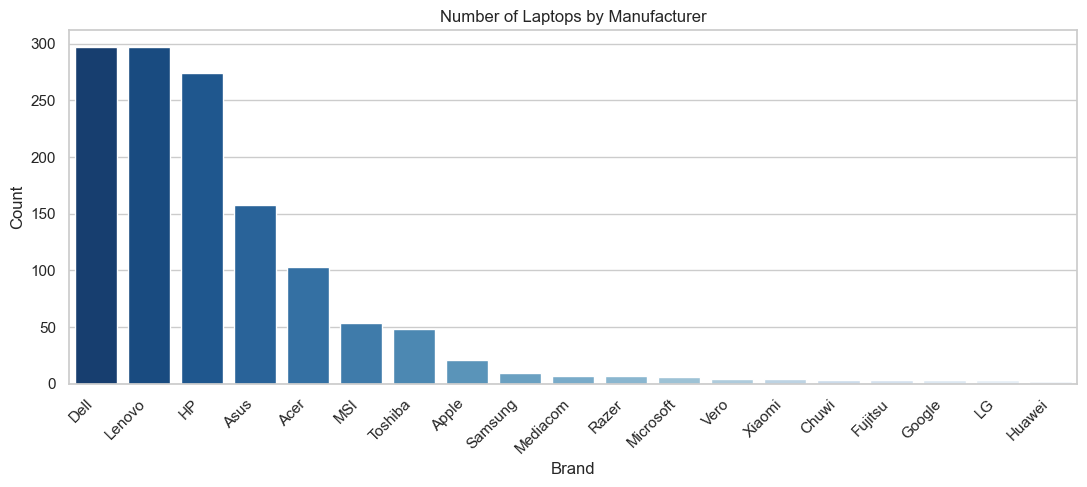

In [11]:
# Visualization 2: Laptop Brand (Company) Frequency
fig, ax = plt.subplots(figsize=(11, 5))
brand_counts = df['Company'].value_counts()
sns.barplot(x=brand_counts.index, y=brand_counts.values, palette='Blues_r', ax=ax)
ax.set_title("Number of Laptops by Manufacturer")
ax.set_xlabel("Brand")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Observation:**
Dell (297 laptops), Lenovo (297 laptops), and HP (274 laptops) represent the vast majority of records in the dataset. Together, these top three brands make up over 66% of all observations. Other well-known brands like Asus (158) and Acer (103) also have substantial representation, while niche brands like Razer, Xiaomi, Google, and LG have fewer than 10 records each.

**Interpretation:**
The dataset reflects a real-world market dominance of the primary commercial PC vendors (Dell, HP, Lenovo). The smaller sample sizes for boutique brands mean our model will have fewer examples to learn brand-specific price markups for minor manufacturers.

**Takeaway:**
One-hot encoding `Company` is appropriate, but we must ensure our train-test split handles these low-frequency brands properly without causing out-of-vocabulary errors on the test set.


<cell_13>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



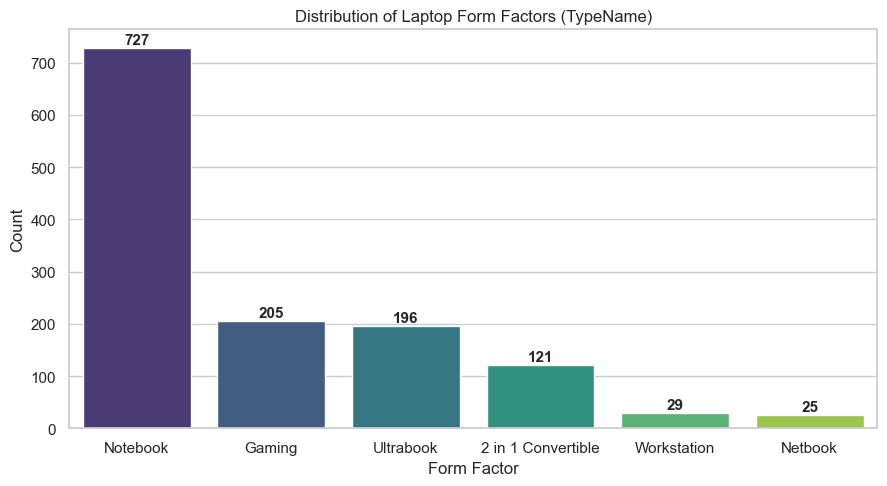

In [12]:
# Visualization 3: Laptop Form Factor (TypeName) Frequency
fig, ax = plt.subplots(figsize=(9, 5))
type_counts = df['TypeName'].value_counts()
sns.barplot(x=type_counts.index, y=type_counts.values, palette='viridis', ax=ax)
ax.set_title("Distribution of Laptop Form Factors (TypeName)")
ax.set_xlabel("Form Factor")
ax.set_ylabel("Count")
for i, v in enumerate(type_counts.values):
    ax.text(i, v + 8, str(v), ha='center', fontweight='semibold')
plt.tight_layout()
plt.show()


**Observation:**
Standard "Notebook" is by far the most common category with 727 machines (55.8% of the dataset). Gaming laptops (205) and Ultrabooks (196) form the next largest groups, followed by 2 in 1 Convertibles (121). Workstations (29) and Netbooks (25) are relatively rare.

**Interpretation:**
Everyday consumer notebooks make up the core of the market. Performance-oriented categories like Gaming laptops and Workstations have fewer entries, yet as we will see, they represent a significant portion of higher-priced machines.

**Takeaway:**
`TypeName` is a key categorical feature that captures the intended use and build style of the machine.


<cell_14>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



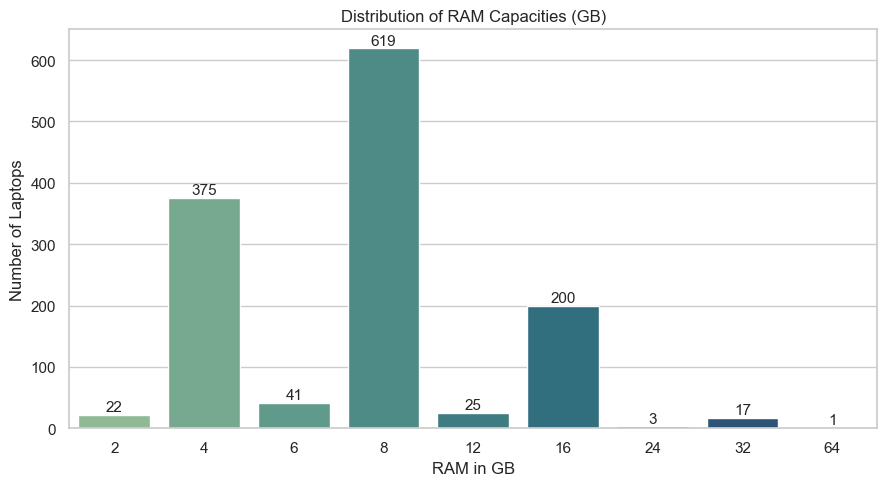

In [13]:
# Visualization 4: RAM Capacity Distribution
fig, ax = plt.subplots(figsize=(9, 5))
ram_order = sorted(df['Ram_GB'].unique())
sns.countplot(data=df, x='Ram_GB', order=ram_order, palette='crest', ax=ax)
ax.set_title("Distribution of RAM Capacities (GB)")
ax.set_xlabel("RAM in GB")
ax.set_ylabel("Number of Laptops")
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{int(height)}", (p.get_x() + p.get_width() / 2., height + 6), ha='center')
plt.tight_layout()
plt.show()


**Observation:**
8GB RAM is the most common capacity with 619 laptops (47.5%), followed by 4GB RAM with 375 laptops (28.8%), and 16GB RAM with 200 laptops (15.3%). Rare configurations include 2GB, 6GB, 12GB, 24GB, 32GB, and a single 64GB machine.

**Interpretation:**
Standard laptops are built in power-of-two memory steps (4GB, 8GB, 16GB). Very few laptops have odd memory capacities like 6GB or 12GB, which typically occur when an asymmetric RAM stick is added. High RAM capacities (>= 16GB) are reserved for premium devices.

**Takeaway:**
Treating `Ram_GB` as a continuous or ordered integer is logical because memory capacity directly increases system capability and hardware cost.


<cell_15>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



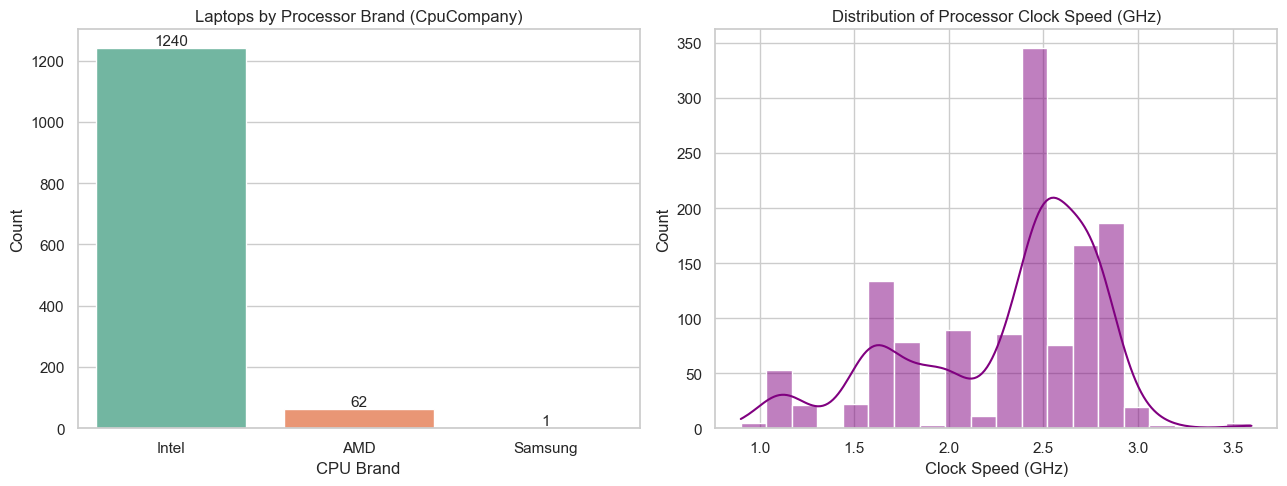

In [14]:
# Visualization 5: CPU Company and Clock Speed Distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# CPU Company
sns.countplot(data=df, x='CpuCompany', palette='Set2', ax=axes[0])
axes[0].set_title("Laptops by Processor Brand (CpuCompany)")
axes[0].set_xlabel("CPU Brand")
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2., p.get_height() + 10), ha='center')

# Clock Speed
sns.histplot(df['ClockSpeed'], kde=True, color='purple', bins=20, ax=axes[1])
axes[1].set_title("Distribution of Processor Clock Speed (GHz)")
axes[1].set_xlabel("Clock Speed (GHz)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


**Observation:**
Intel massively dominates the dataset with 1,240 laptops (95.2%). AMD powers 62 laptops (4.8%), and Samsung appears on exactly 1 record. Clock speeds range from 0.9GHz to 3.6GHz, with major peaks around 2.5GHz, 2.7GHz, and 2.8GHz.

**Interpretation:**
During the era when this data was collected (around 2016–2017), Intel held near-monopoly status in consumer laptops. The clock speed peaks reflect standard mainstream mobile chips of the time (such as the Core i5-7200U at 2.5GHz and Core i7-7700HQ at 2.8GHz).

**Takeaway:**
`CpuCompany` shows heavy class imbalance. `ClockSpeed` is a useful continuous feature that correlates with processing power.


<cell_16>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



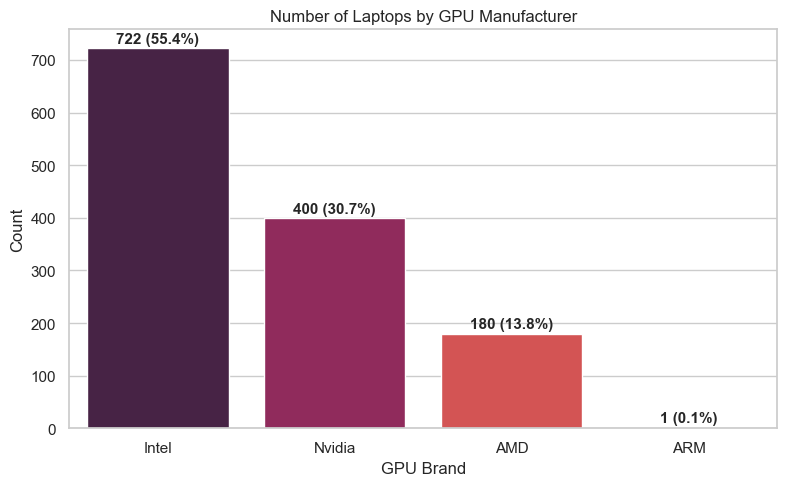

In [15]:
# Visualization 6: GPU Silicon Brand Distribution
fig, ax = plt.subplots(figsize=(8, 5))
gpu_counts = df['GpuBrand'].value_counts()
sns.barplot(x=gpu_counts.index, y=gpu_counts.values, palette='rocket', ax=ax)
ax.set_title("Number of Laptops by GPU Manufacturer")
ax.set_xlabel("GPU Brand")
ax.set_ylabel("Count")
for i, v in enumerate(gpu_counts.values):
    ax.text(i, v + 10, f"{v} ({round(v/len(df)*100, 1)}%)", ha='center', fontweight='semibold')
plt.tight_layout()
plt.show()


**Observation:**
Intel graphics leads with 722 laptops (55.4%), followed by Nvidia with 400 laptops (30.7%), AMD with 180 laptops (13.8%), and ARM on 1 laptop.

**Interpretation:**
Over half the laptops rely on integrated Intel graphics (like Intel HD Graphics 620), which is standard for office and school notebooks. Dedicated Nvidia graphics chips are present in roughly 31% of laptops, representing gaming laptops and mobile workstations.

**Takeaway:**
`GpuBrand` provides a clear signal distinguishing machines with integrated basic graphics from those with power-hungry, high-cost dedicated graphics cards.


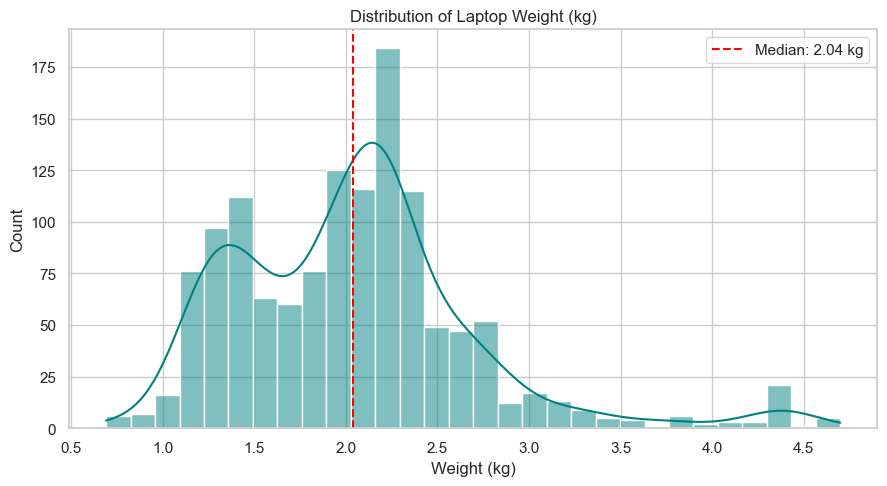

In [16]:
# Visualization 7: Laptop Weight Distribution
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['Weight_kg'], kde=True, color='teal', bins=30, ax=ax)
ax.axvline(df['Weight_kg'].median(), color='red', linestyle='--', label=f"Median: {df['Weight_kg'].median():.2f} kg")
ax.set_title("Distribution of Laptop Weight (kg)")
ax.set_xlabel("Weight (kg)")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()


**Observation:**
Laptop weights form a bell-shaped distribution centered around 2.0kg to 2.2kg, with a median of 2.04kg. Lightweight ultrabooks weigh as little as 0.69kg to 1.2kg, while heavy 17-inch gaming laptops and desktop replacements reach 3.5kg to 4.7kg.

**Interpretation:**
Standard 15.6-inch notebooks generally weigh around 2kg. Very low weights indicate expensive ultraportable engineering (magnesium/carbon chassis), while very high weights indicate heavy cooling systems for gaming GPUs.

**Takeaway:**
Weight alone does not have a simple linear relationship with price; both very light ultrabooks and very heavy gaming laptops can be expensive.


<cell_18>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<cell_18>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



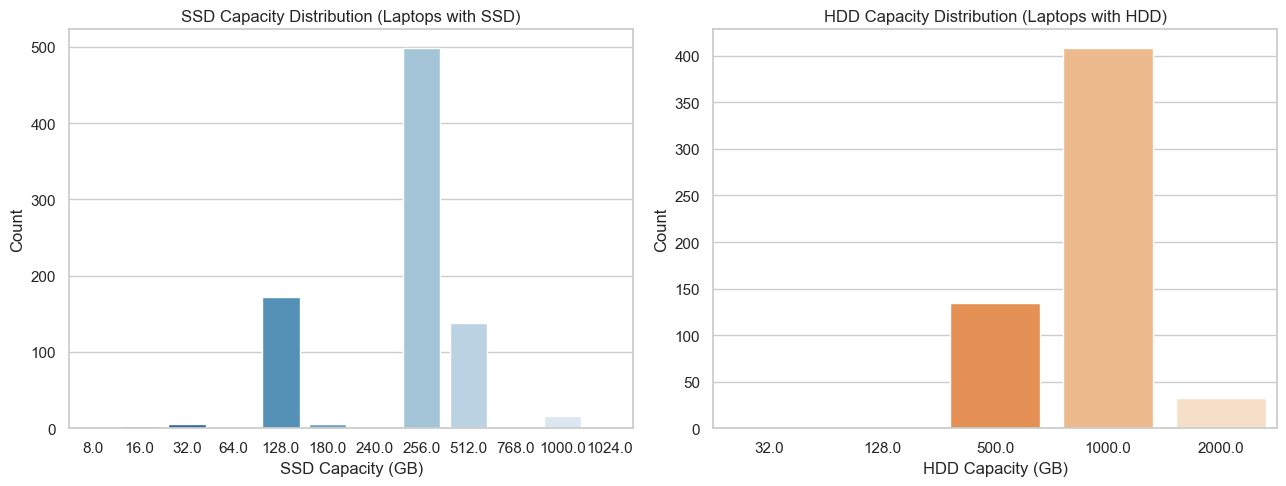

In [17]:
# Visualization 8: SSD and HDD Capacities
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df[df['SSD_GB'] > 0], x='SSD_GB', palette='Blues_r', ax=axes[0])
axes[0].set_title("SSD Capacity Distribution (Laptops with SSD)")
axes[0].set_xlabel("SSD Capacity (GB)")
axes[0].set_ylabel("Count")

sns.countplot(data=df[df['HDD_GB'] > 0], x='HDD_GB', palette='Oranges_r', ax=axes[1])
axes[1].set_title("HDD Capacity Distribution (Laptops with HDD)")
axes[1].set_xlabel("HDD Capacity (GB)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


**Observation:**
For solid-state drives, 256GB is the dominant size (508 laptops), followed by 128GB (172) and 512GB (140). For mechanical hard drives, 1000GB (1TB) is by far the most popular size (415 laptops), followed by 500GB (132).

**Interpretation:**
Consumers during this period were commonly offered either a fast 256GB SSD for responsiveness or a slower, high-capacity 1TB mechanical drive for bulk storage. Some performance laptops combined both (e.g. 128GB SSD + 1TB HDD).

**Takeaway:**
`SSD_GB` and `HDD_GB` are informative numerical features that represent modern solid-state speed versus legacy storage capacity.


## 8. Bivariate Analysis with Laptop Price

Now we investigate how individual features relate directly to the selling price.


<cell_19>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



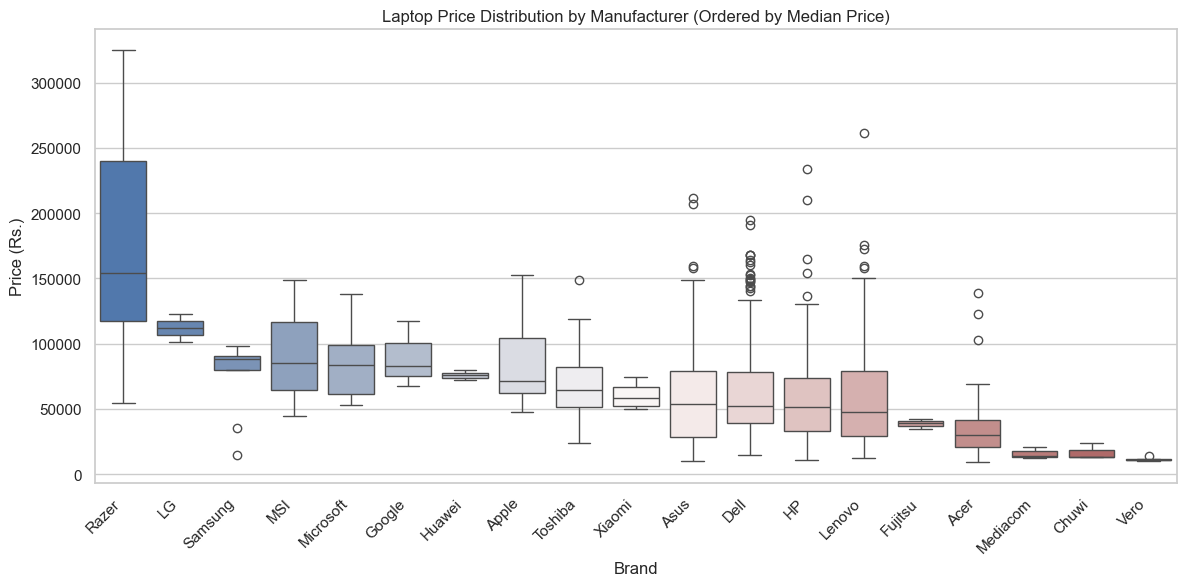

In [18]:
# Visualization 9: Company vs Price
fig, ax = plt.subplots(figsize=(12, 6))
company_order = df.groupby('Company')['Price'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Company', y='Price', order=company_order, palette='vlag', ax=ax)
ax.set_title("Laptop Price Distribution by Manufacturer (Ordered by Median Price)")
ax.set_xlabel("Brand")
ax.set_ylabel("Price (Rs.)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**Observation:**
Razer has the highest median price by far (over Rs. 1,40,000), followed by LG, Google, Apple, and MSI. Mainstream brands like Dell, HP, Lenovo, and Asus span wide ranges from budget models under Rs. 20,000 to high-end workstations over Rs. 1,50,000. Brands like Acer, Mediacom, and Vero have much lower median prices.

**Interpretation:**
Boutique gaming brands (Razer) and premium ecosystems (Apple, Google) sell almost exclusively higher-end devices. In contrast, mass-market manufacturers (Dell, HP, Lenovo) serve all market segments, which produces extensive price spreads and several upper outliers.

**Takeaway:**
Brand name is a meaningful pricing factor, but for the large brands, internal specifications will be the primary driver separating cheap models from expensive ones.


<cell_20>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



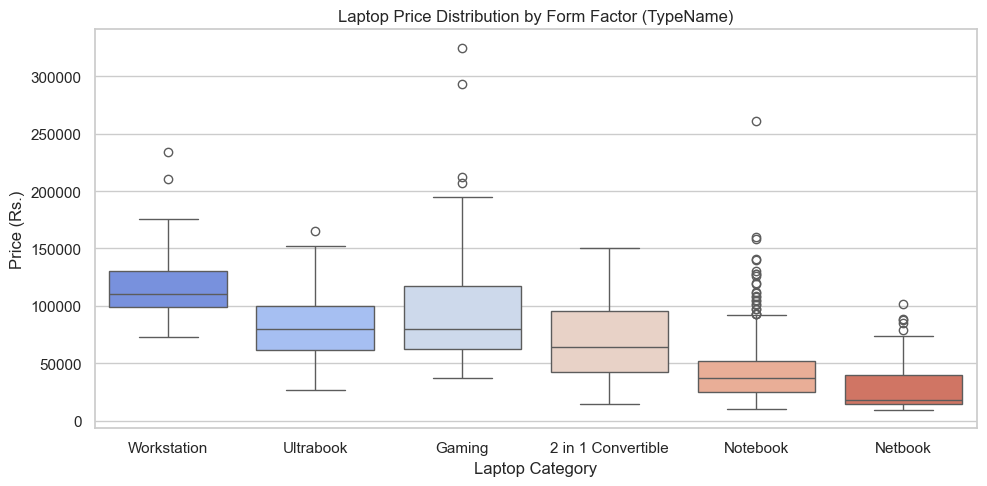

In [19]:
# Visualization 10: TypeName vs Price
fig, ax = plt.subplots(figsize=(10, 5))
type_order = df.groupby('TypeName')['Price'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='TypeName', y='Price', order=type_order, palette='coolwarm', ax=ax)
ax.set_title("Laptop Price Distribution by Form Factor (TypeName)")
ax.set_xlabel("Laptop Category")
ax.set_ylabel("Price (Rs.)")
plt.tight_layout()
plt.show()


**Observation:**
Workstations command the highest median price (over Rs. 90,000), followed by Gaming laptops and Ultrabooks. Standard consumer Notebooks and small Netbooks occupy the lowest price ranges, with Netbooks rarely exceeding Rs. 30,000.

**Interpretation:**
Form factor reflects target audience and build quality. Workstations and Gaming laptops require expensive cooling, high-end silicon, and durable components. Ultrabooks demand high-density engineering for thinness. Standard Notebooks prioritize cost-effective utility.

**Takeaway:**
`TypeName` is one of the strongest categorical predictors of laptop price.


<cell_21>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



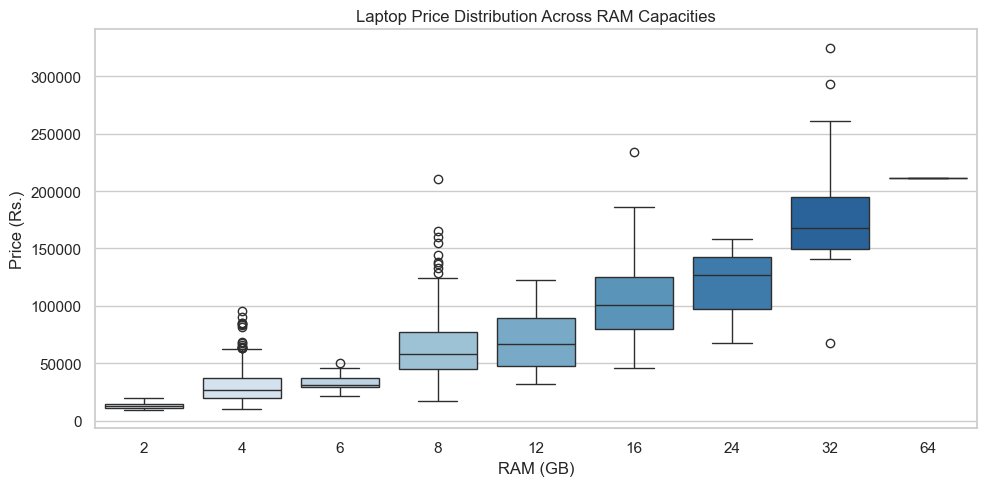

In [20]:
# Visualization 11: RAM vs Price
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x='Ram_GB', y='Price', palette='Blues', ax=ax)
ax.set_title("Laptop Price Distribution Across RAM Capacities")
ax.set_xlabel("RAM (GB)")
ax.set_ylabel("Price (Rs.)")
plt.tight_layout()
plt.show()


**Observation:**
There is a clear, monotonic relationship between RAM capacity and laptop price. Laptops with 4GB RAM have a median price around Rs. 29,000, 8GB jumps to approximately Rs. 50,000, 16GB climbs above Rs. 1,00,000, and 32GB approaches Rs. 1,70,000. 

**Interpretation:**
RAM is a direct proxy for machine tier. Manufacturers rarely pair large RAM capacities with weak processors or cheap displays. When a buyer chooses 16GB or 32GB RAM, the entire underlying machine is almost always an upscale configuration.

**Takeaway:**
RAM will likely be one of the most important numerical features in our regression models.


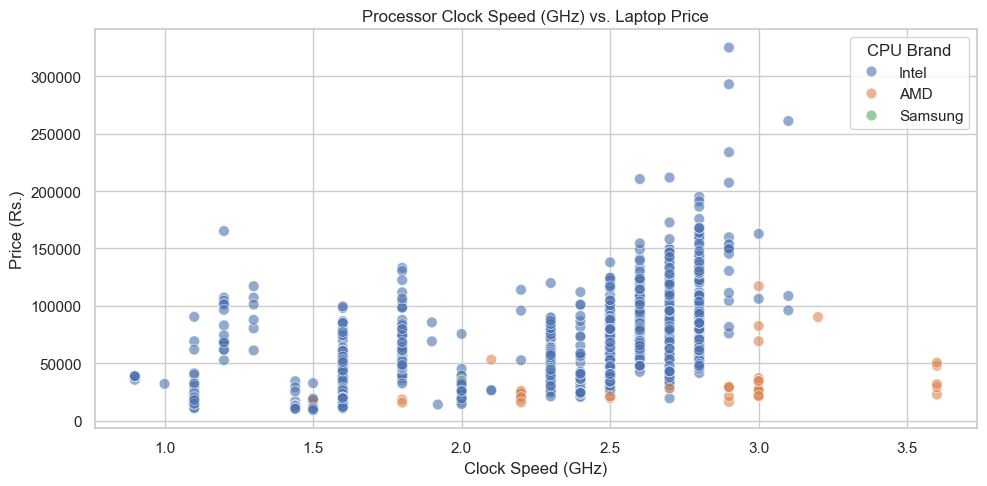

In [21]:
# Visualization 12: CPU Clock Speed vs Price
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=df, x='ClockSpeed', y='Price', hue='CpuCompany', alpha=0.6, palette='deep', s=60, ax=ax)
ax.set_title("Processor Clock Speed (GHz) vs. Laptop Price")
ax.set_xlabel("Clock Speed (GHz)")
ax.set_ylabel("Price (Rs.)")
ax.legend(title="CPU Brand")
plt.tight_layout()
plt.show()


**Observation:**
Higher clock speeds generally correlate with higher prices, especially above 2.5GHz. Most high-priced laptops over Rs. 1,00,000 have clock speeds between 2.6GHz and 3.1GHz. Laptops with clock speeds below 1.5GHz are predominantly clustered in the lower price tier under Rs. 30,000.

**Interpretation:**
Entry-level processors (like Celeron and Atom) operate at low clock speeds and cost very little. High-performance processors (like Core i7 and Xeon) operate at higher frequencies and carry substantial premiums.

**Takeaway:**
`ClockSpeed` provides a helpful continuous signal of CPU performance.


<cell_23>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



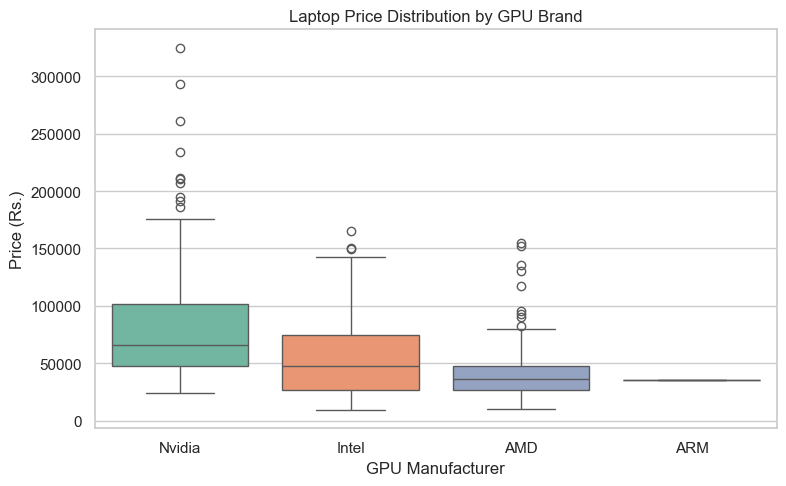

In [22]:
# Visualization 13: GPU Brand vs Price
fig, ax = plt.subplots(figsize=(8, 5))
gpu_order = df.groupby('GpuBrand')['Price'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='GpuBrand', y='Price', order=gpu_order, palette='Set2', ax=ax)
ax.set_title("Laptop Price Distribution by GPU Brand")
ax.set_xlabel("GPU Manufacturer")
ax.set_ylabel("Price (Rs.)")
plt.tight_layout()
plt.show()


**Observation:**
Laptops with Nvidia GPUs show a significantly higher median price (nearly Rs. 70,000) and reach all the highest price extremes (up to Rs. 3.2 Lakh) compared to Intel (median ~Rs. 48,000) and AMD (median ~Rs. 29,000).

**Interpretation:**
Nvidia GPUs in this dataset represent dedicated discrete graphics cards (such as GeForce GTX 1050 to 1080 and Quadro chips), which are added exclusively to performance and gaming laptops. Intel chips are mostly integrated on-die graphics that add no extra hardware cost.

**Takeaway:**
`GpuBrand` acts as an effective indicator for dedicated graphics capability.


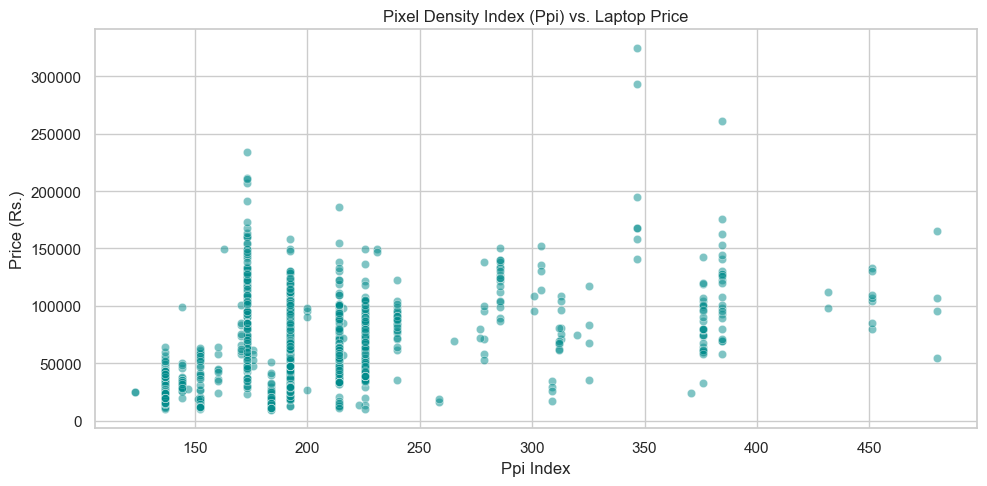

In [23]:
# Visualization 14: PPI vs Price
fig, ax = plt.subplots(figsize=(10, 5))
sns.scatterplot(data=df, x='Ppi', y='Price', alpha=0.5, color='darkcyan', ax=ax)
ax.set_title("Pixel Density Index (Ppi) vs. Laptop Price")
ax.set_xlabel("Ppi Index")
ax.set_ylabel("Price (Rs.)")
plt.tight_layout()
plt.show()


**Observation:**
There is a positive upward trend between pixel density (`Ppi`) and price. Laptops with lower PPI (e.g. 140–180, corresponding to standard 1366x768 screens) cluster at lower prices under Rs. 40,000. Higher PPI values (above 200, corresponding to Full HD, Retina, and 4K displays) span a much wider, higher price range.

**Interpretation:**
Sharper, higher-resolution panels cost more to produce and are typically installed in premium laptops with better overall build quality.

**Takeaway:**
Screen pixel density combines screen size and resolution into a single continuous feature that correlates positively with laptop price.


<cell_25>:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



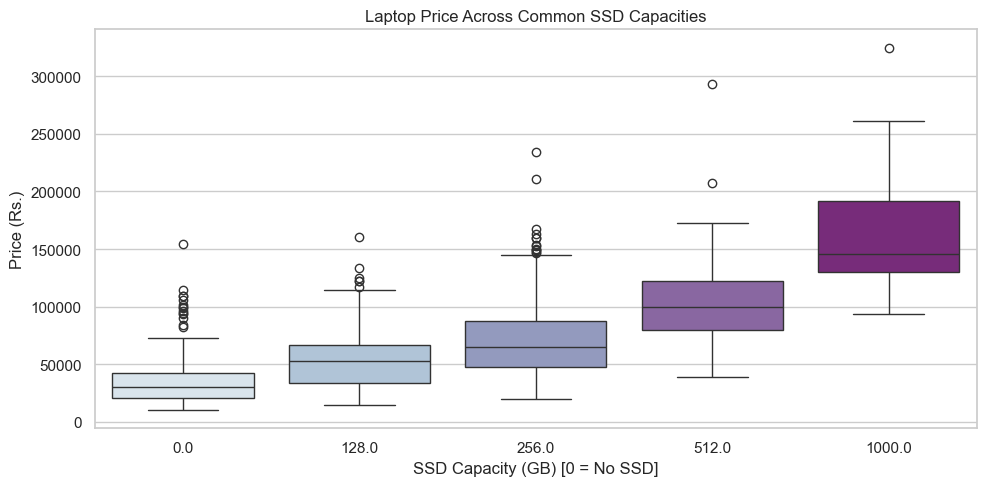

In [24]:
# Visualization 15: SSD Capacity vs Price
fig, ax = plt.subplots(figsize=(10, 5))
top_ssd_capacities = [0, 128, 256, 512, 1000]
sub_ssd = df[df['SSD_GB'].isin(top_ssd_capacities)]
sns.boxplot(data=sub_ssd, x='SSD_GB', y='Price', palette='BuPu', ax=ax)
ax.set_title("Laptop Price Across Common SSD Capacities")
ax.set_xlabel("SSD Capacity (GB) [0 = No SSD]")
ax.set_ylabel("Price (Rs.)")
plt.tight_layout()
plt.show()


**Observation:**
Laptops with 0GB SSD (relying solely on HDD or Flash storage) have a median price near Rs. 31,000. Adding a 128GB SSD increases the median to ~Rs. 48,000, 256GB reaches ~Rs. 60,000, and 512GB reaches nearly Rs. 1,00,000. 1TB SSD laptops have a median exceeding Rs. 1,30,000.

**Interpretation:**
Solid-state drive capacity is one of the clearest premium indicators in modern computing. Fast solid-state storage carries both direct component cost and acts as a marker for high-tier machines.

**Takeaway:**
`SSD_GB` provides strong predictive signal for regression.


## 9. Correlation & Multivariate Analysis

Let us calculate Pearson correlation coefficients across numerical variables and visualize them in a heatmap.


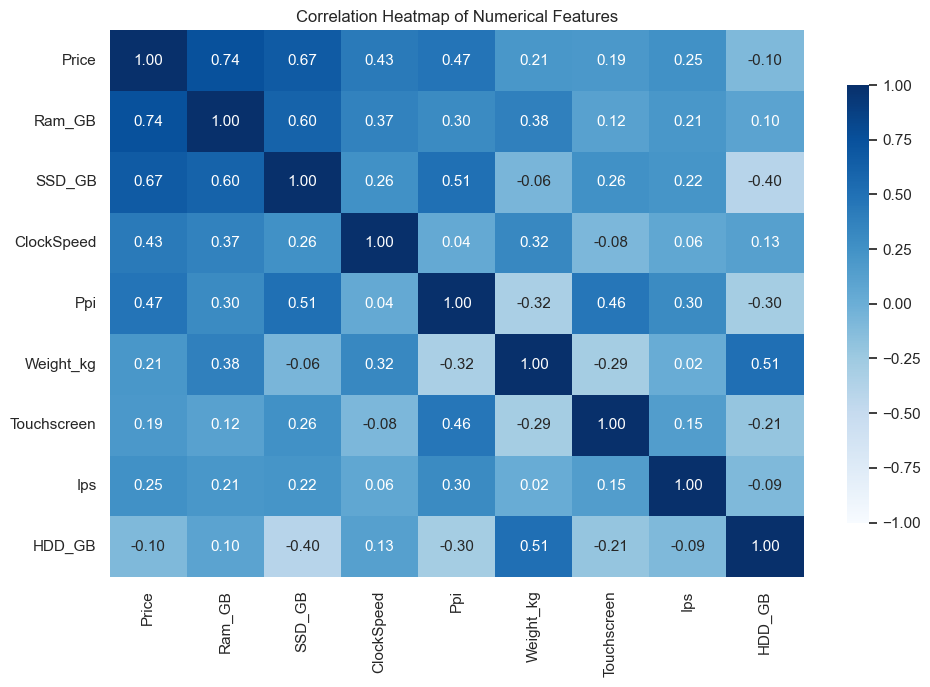

In [25]:
# Visualization 16: Correlation Heatmap of Numerical Features
num_cols = ['Price', 'Ram_GB', 'SSD_GB', 'ClockSpeed', 'Ppi', 'Weight_kg', 'Touchscreen', 'Ips', 'HDD_GB']
corr_matrix = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


**Observation:**
`Ram_GB` exhibits the highest positive linear correlation with `Price` (r = 0.74), followed closely by `SSD_GB` (r = 0.67), `Ppi` (r = 0.47), and `ClockSpeed` (r = 0.43). `HDD_GB` shows a mild negative correlation with price (r = -0.10). Features like `Weight_kg` and `Touchscreen` show weak overall linear correlation with price (r = 0.21 and r = 0.19).

**Interpretation:**
Laptop price is primarily driven by performance-enhancing hardware: RAM and SSD storage. Mechanical HDDs correlate negatively because they are cheaper components typically found in budget models. The low linear correlation of `Weight_kg` aligns with our earlier finding that both very light ultrabooks and heavy gaming laptops can be expensive.

**Takeaway:**
The features show clear, logical relationships with the target without extreme collinearity among predictors (no pair of independent variables exceeds r = 0.60).


<cell_27>:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.



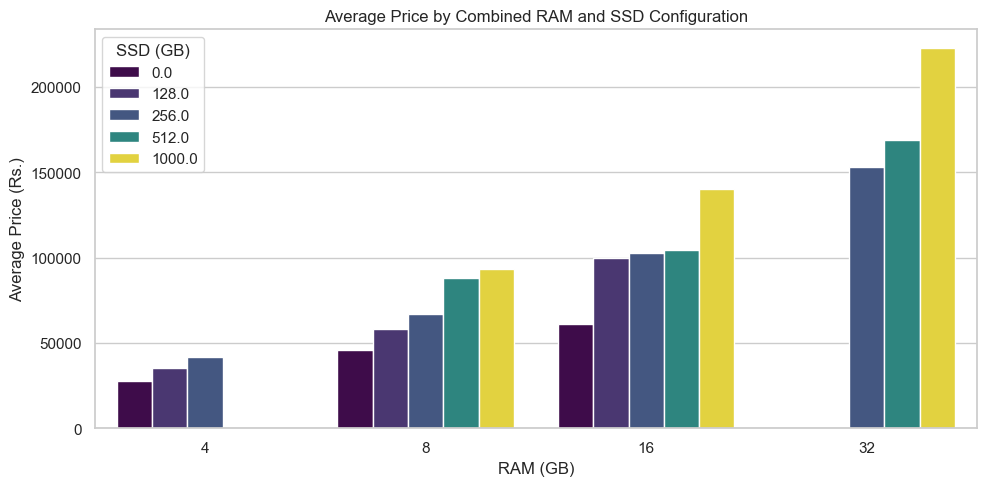

In [26]:
# Visualization 17: Multivariate Interaction: RAM and SSD Capacity
fig, ax = plt.subplots(figsize=(10, 5))
common_rams = [4, 8, 16, 32]
common_ssds = [0, 128, 256, 512, 1000]
sub_multi = df[(df['Ram_GB'].isin(common_rams)) & (df['SSD_GB'].isin(common_ssds))]
sns.barplot(data=sub_multi, x='Ram_GB', y='Price', hue='SSD_GB', palette='viridis', ci=None, ax=ax)
ax.set_title("Average Price by Combined RAM and SSD Configuration")
ax.set_xlabel("RAM (GB)")
ax.set_ylabel("Average Price (Rs.)")
ax.legend(title="SSD (GB)")
plt.tight_layout()
plt.show()


**Observation:**
For any given RAM capacity, adding or increasing SSD storage consistently increases the average price. Conversely, for any given SSD size, stepping up the RAM also raises the price. A laptop with 4GB RAM and no SSD averages under Rs. 25,000, while a laptop with 32GB RAM and 1TB SSD averages well over Rs. 2,00,000.

**Interpretation:**
RAM and SSD storage reinforce each other. High memory and fast storage represent a compounded premium where high-end components are bundled together by manufacturers.

**Takeaway:**
Tree-based ensemble models (Random Forest, Gradient Boosting) are especially well-suited for capturing these multi-feature interaction effects without requiring manual polynomial feature engineering.


## 10. Outlier Investigation (Tukey's IQR Method)

We apply Tukey's standard Interquartile Range (IQR) rule:
- $\text{IQR} = Q3 - Q1$
- $\text{Lower Bound} = Q1 - 1.5 \times \text{IQR}$
- $\text{Upper Bound} = Q3 + 1.5 \times \text{IQR}$

Let us recalculate the boundaries directly from our dataset and inspect the records that fall outside these thresholds.


In [27]:
# Calculate IQR boundaries and outlier counts
eval_features = ['Ram_GB', 'Weight_kg', 'ClockSpeed', 'Ppi', 'Price', 'SSD_GB', 'HDD_GB']
iqr_summary = []

for feat in eval_features:
    q1 = df[feat].quantile(0.25)
    med = df[feat].median()
    q3 = df[feat].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[(df[feat] < lower) | (df[feat] > upper)]
    count = len(outliers)
    pct = round((count / len(df)) * 100, 2)
    
    iqr_summary.append({
        'Feature': feat,
        'Q1 (25%)': round(q1, 2),
        'Median': round(med, 2),
        'Q3 (75%)': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower, 2),
        'Upper Bound': round(upper, 2),
        'Outlier Count': count,
        'Outlier Pct (%)': pct
    })

df_iqr = pd.DataFrame(iqr_summary)
print("--- IQR Outlier Summary Table ---")
display(df_iqr)


--- IQR Outlier Summary Table ---


,Feature,Q1 (25%),Median,Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Pct (%)
0,Ram_GB,4.00,8.00,8.00,4.00,-2.00,14.00,221,16.96
1,Weight_kg,1.50,2.04,2.30,0.80,0.30,3.50,46,3.53
2,ClockSpeed,2.00,2.50,2.70,0.70,0.95,3.75,4,0.31
3,Ppi,173.41,192.31,214.29,40.88,112.10,275.60,124,9.52
4,Price,31914.72,52054.56,79274.25,47359.53,-39124.57,150313.54,29,2.23
5,SSD_GB,0.00,256.00,256.00,256.00,-384.00,640.00,18,1.38
6,HDD_GB,0.00,0.00,1000.00,1000.00,-1500.00,2500.00,0,0.00


In [28]:
# Inspecting the 29 Price Statistical Outliers (> Rs. 1,50,313.54)
price_upper = df_iqr.loc[df_iqr['Feature'] == 'Price', 'Upper Bound'].values[0]
price_outliers = df[df['Price'] > price_upper].sort_values(by='Price', ascending=False)

print(f"Total Price Outliers above Upper Bound (Rs. {price_upper:,.2f}): {len(price_outliers)}")
print("\nTop 10 Price Outlier Records:")
display(price_outliers[['Company', 'TypeName', 'Cpu', 'Ram_GB', 'Memory', 'Gpu', 'Price']].head(10))


Total Price Outliers above Upper Bound (Rs. 150,313.54): 29

Top 10 Price Outlier Records:


,Company,TypeName,Cpu,Ram_GB,Memory,Gpu,Price
196,Razer,Gaming,Intel Core i7 7820HK 2.9GHz,32,1TB SSD,Nvidia GeForce GTX 1080,324954.720
830,Razer,Gaming,Intel Core i7 7820HK 2.9GHz,32,512GB SSD,Nvidia GeForce GTX 1080,292986.720
610,Lenovo,Notebook,Intel Xeon E3-1535M v6 3.1GHz,32,1TB SSD,Nvidia Quadro M2200M,261018.720
749,HP,Workstation,Intel Xeon E3-1535M v5 2.9GHz,16,256GB SSD,Nvidia Quadro M2000M,233845.920
1066,Asus,Gaming,Intel Core i7 6820HK 2.7GHz,64,1TB SSD,Nvidia GeForce GTX 980,211788.000
1136,HP,Workstation,Intel Core i7 6700HQ 2.6GHz,8,256GB SSD,Nvidia Quadro M3000M,210424.032
238,Asus,Gaming,Intel Core i7 7820HK 2.9GHz,32,512GB SSD + 1TB HDD,Nvidia GeForce GTX 1080,207259.200
723,Dell,Gaming,Intel Core i7 7700HQ 2.8GHz,32,1TB SSD + 1TB HDD,Nvidia GeForce GTX 1070,194972.832
780,Dell,Gaming,Intel Core i7 7700HQ 2.8GHz,32,1TB SSD + 1TB HDD,Nvidia GeForce GTX 1070M,191211.264
1231,Razer,Gaming,Intel Core i7 7700HQ 2.8GHz,16,1TB SSD,Nvidia GeForce GTX 1060,186426.720


### Outlier Findings & Decision:
1. **Verification of Counts:**
   - `Ram_GB`: **221 outliers** (all machines with $\ge 16\text{GB}$ RAM, because Q3 is 8GB and Upper Bound is 14GB).
   - `Weight_kg`: **46 outliers** (machines $> 3.5\text{kg}$, mostly large 17.3-inch gaming laptops).
   - `ClockSpeed`: **4 outliers** (machines at 0.9GHz, representing ultra-low power Core M).
   - `Ppi`: **124 outliers** (displays $> 275.6$, representing 4K and Retina displays).
   - `Price`: **29 outliers** (machines above Rs. 1,50,313.54).
   - `SSD_GB`: **18 outliers** (machines with 768GB or 1000GB SSDs).
   - `HDD_GB`: **0 outliers** (all values fall within -1500GB to 2500GB).
2. **Are the Price Outliers Errors or Genuine?**
   - The top priced laptops include:
     - **Razer Gaming (Rs. 3,24,954):** 32GB RAM, 1TB SSD, 4K screen, Core i7-7820HK, Nvidia GTX 1080.
     - **Lenovo Workstation (Rs. 2,61,018):** 32GB RAM, 1TB SSD, 4K screen, Intel Xeon E3-1535M, Nvidia Quadro M2200M.
     - **HP Workstation (Rs. 2,33,845):** 16GB RAM, Intel Xeon, Nvidia Quadro M2000M.
     - **Asus Gaming (Rs. 2,11,788):** 64GB RAM, 1TB SSD, GTX 980.
   - **Conclusion:** These laptops are **100% genuine, legitimate luxury and enterprise hardware**. They are statistical outliers only because the majority of consumer laptops are inexpensive. **We must NOT delete or clip them**, as doing so would blind the model to high-performance machines.


## 11. Storage Configuration Analysis

Laptops use various storage architectures. Let us audit how storage technologies are combined across the dataset.


In [29]:
# Classify storage architectures
def classify_storage_combination(row):
    has_ssd = row['SSD_GB'] > 0
    has_hdd = row['HDD_GB'] > 0
    has_flash = row['Flash_GB'] > 0
    has_hybrid = row['Hybrid_GB'] > 0
    
    types = []
    if has_ssd: types.append('SSD')
    if has_hdd: types.append('HDD')
    if has_flash: types.append('Flash Storage')
    if has_hybrid: types.append('Hybrid')
    
    if len(types) == 0:
        return 'No Storage Listed'
    elif len(types) == 1:
        return f"{types[0]} only"
    else:
        return " + ".join(types)

df['Storage_Configuration'] = df.apply(classify_storage_combination, axis=1)

storage_table = []
for config, count in df['Storage_Configuration'].value_counts().items():
    sub = df[df['Storage_Configuration'] == config]
    storage_table.append({
        'Storage Configuration': config,
        'Records': count,
        'Percentage (%)': round((count / len(df)) * 100, 2),
        'Median Price (Rs.)': round(sub['Price'].median(), 2),
        'Mean Price (Rs.)': round(sub['Price'].mean(), 2)
    })

df_storage_audit = pd.DataFrame(storage_table)
print("--- Storage Configuration Distribution ---")
display(df_storage_audit)

# Check if any record has all 4 storage values equal to zero
zero_storage_count = (df['Storage_Configuration'] == 'No Storage Listed').sum()
print(f"\nRecords with zero total storage: {zero_storage_count}")


--- Storage Configuration Distribution ---

Records with zero total storage: 0


,Storage Configuration,Records,Percentage (%),Median Price (Rs.),Mean Price (Rs.)
0,SSD only,641,49.19,63669.60,69992.81
1,HDD only,375,28.78,31861.44,34914.26
2,SSD + HDD,200,15.35,74458.80,85964.96
3,Flash Storage only,74,5.68,17555.76,27055.89
4,Hybrid only,10,0.77,45820.80,43196.55
5,SSD + Hybrid,2,0.15,159573.33,159573.33
6,HDD + Flash Storage,1,0.08,106187.04,106187.04


### Storage Configuration Findings:
- **Verified Breakdown:**
  - `SSD only`: **641 laptops (49.19%)**, Median Price = Rs. 63,670
  - `HDD only`: **375 laptops (28.78%)**, Median Price = Rs. 31,861
  - `SSD + HDD`: **200 laptops (15.35%)**, Median Price = Rs. 74,459
  - `Flash Storage only`: **74 laptops (5.68%)**, Median Price = Rs. 17,556
  - `Hybrid only`: **10 laptops (0.77%)**, Median Price = Rs. 45,821
  - `SSD + Hybrid`: **2 laptops (0.15%)**, Median Price = Rs. 1,59,573
  - `HDD + Flash Storage`: **1 laptop (0.08%)**, Price = Rs. 1,06,187
- **Zero Storage Check:** Exactly **0 laptops** have all four values equal to zero. Every single observation has verified storage capacity.
- **Price Insights:** Fast solid-state storage commands a massive premium over mechanical storage. Laptops with only an SSD cost almost twice as much as HDD-only machines, and dual-drive laptops (SSD for speed + HDD for capacity) command the highest mainstream median price (Rs. 74,459).


## 12. Screen Pixel Density (PPI) Feature Investigation

In this project, we discovered an interesting mathematical detail about the `Ppi` feature.

### Two Formulas for Pixel Density:
1. **The Standard Physical Formula (Euclidean / Pythagorean):**
   $$\text{PPI}_{\text{standard}} = \frac{\sqrt{\text{Width}^2 + \text{Height}^2}}{\text{Inches}}$$
   This represents the true number of physical pixels along the screen's diagonal per inch.

2. **The Dataset-Specific Formula (Manhattan distance):**
   $$\text{Ppi}_{\text{dataset}} = \frac{\text{Width} + \text{Height}}{\text{Inches}}$$
   This formula sums the horizontal and vertical resolution and divides by diagonal inches.

Let us compare both formulas on our dataset.


In [30]:
# Compare Manhattan vs Euclidean PPI
print("Sample Comparison of PPI Calculations:")
ppi_samples = df[['ScreenResolution', 'Inches', 'Ppi', 'Ppi_Standard']].drop_duplicates().head(5)
ppi_samples.columns = ['Resolution String', 'Inches', 'Dataset Ppi (Manhattan)', 'Physical Ppi (Euclidean)']
display(ppi_samples)

r_ppi = np.corrcoef(df['Ppi'], df['Ppi_Standard'])[0, 1]
print(f"\nLinear Correlation between Dataset Ppi and Physical Ppi: r = {r_ppi:.6f}")


Sample Comparison of PPI Calculations:

Linear Correlation between Dataset Ppi and Physical Ppi: r = 0.999933


,Resolution String,Inches,Dataset Ppi (Manhattan),Physical Ppi (Euclidean)
0,IPS Panel Retina Display 2560x1600,13.3,312.781955,226.983005
1,1440x900,13.3,175.939850,127.677940
2,Full HD 1920x1080,15.6,192.307692,141.211998
3,IPS Panel Retina Display 2880x1800,15.4,303.896104,220.534624
5,1366x768,15.6,136.794872,100.454670


### PPI Finding & Technical Decision:
- **Why is the correlation r = 0.9999?**
  Virtually all laptop displays have a 16:9 aspect ratio. If $\text{Width} = \frac{16}{9} \times \text{Height}$:
  $$\frac{\text{Width} + \text{Height}}{\sqrt{\text{Width}^2 + \text{Height}^2}} = \frac{16 + 9}{\sqrt{16^2 + 9^2}} = \frac{25}{\sqrt{337}} \approx 1.3618$$
  Because the aspect ratio is almost constant, Manhattan PPI is an exact scalar multiple ($1.36\times$) of Euclidean PPI.
- **Decision:** The relative ordering and ranking of screen sharpness is fully preserved. In our modeling notebook, we retain the dataset-specific formula to remain directly compatible with the historical baseline, while clearly documenting its physical interpretation here.


## 13. Final EDA Summary & Recommendations for Machine Learning

### Key Observations:
1. **Target Variable (`Price`):** Positively skewed with a long tail of high-end machines. Median is Rs. 52,055; maximum is Rs. 3,24,954.
2. **Key Price Drivers:**
   - **RAM:** Strongest linear predictor ($r = 0.74$). Moving from 8GB to 16GB more than doubles the median price.
   - **SSD Storage:** Second strongest predictor ($r = 0.67$). SSD-equipped laptops command nearly twice the price of HDD-only laptops.
   - **GPU:** Dedicated Nvidia graphics mark performance and gaming laptops, creating a large price boost.
   - **Form Factor:** Workstations and Gaming laptops are significantly more expensive than standard Notebooks and Netbooks.
3. **Data Quality & Integrity:**
   - 0 missing values across all columns.
   - 29 duplicate configuration rows in raw data (to be deduplicated before train-test split in modeling).
   - Zero storage values across drives are valid physical absences, not missing data.
   - Row 563 is a legitimate high-priced machine with an enterprise Nvidia Quadro GPU and 3.4kg chassis; the dataset lacks a product model name, so we describe its specifications rather than unverified commercial names.
4. **Outlier Reality:**
   - The 29 price statistical outliers are genuine luxury gaming rigs and mobile workstations. They must be preserved to allow the model to learn the high-end market.
5. **Dataset Limitations:**
   - Modest sample size (1,303 records).
   - 2016–2017 hardware vintage (Intel 6th/7th Gen, Nvidia GTX 900/10 series).
   - Minimal representation for niche brands (Xiaomi, Google, LG) and ARM/Samsung CPUs.

### Recommendations for the ML Pipeline:
- **Clean Feature Extraction:** Extract clean numbers for `Ram`, `Weight`, `Ppi`, `ClockSpeed`, `SSD`, and `HDD`.
- **Deduplication:** Remove exact specification duplicates before train-test splitting to prevent validation leakage.
- **Model Choice:** Linear Regression serves as our interpretable baseline. Tree-based ensembles (Random Forest, Gradient Boosting) are recommended because they natively handle feature interactions (RAM $\times$ SSD) and non-linear patterns.
- **Leakage-Free Preprocessing:** Fit all encoders and scalers strictly on training data inside a Scikit-Learn `Pipeline` with `ColumnTransformer`.
